# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import ITCVDDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 134


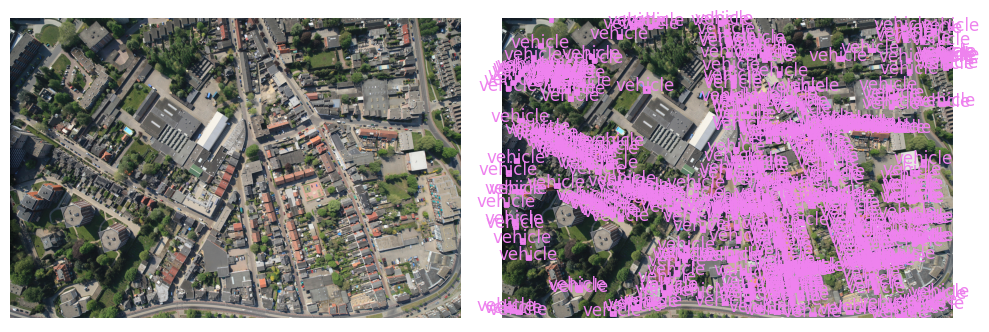

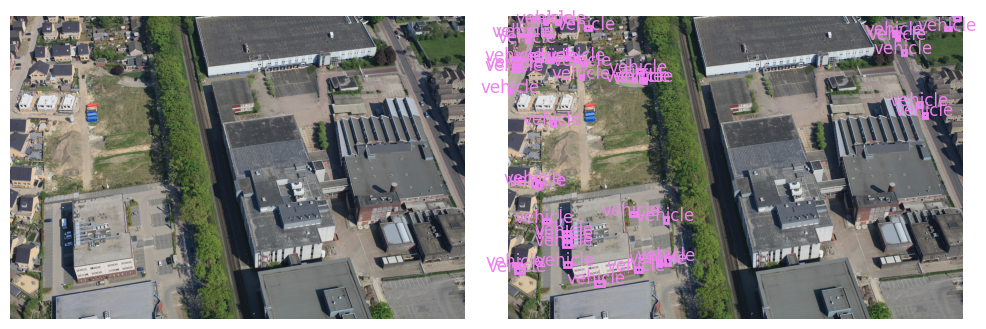

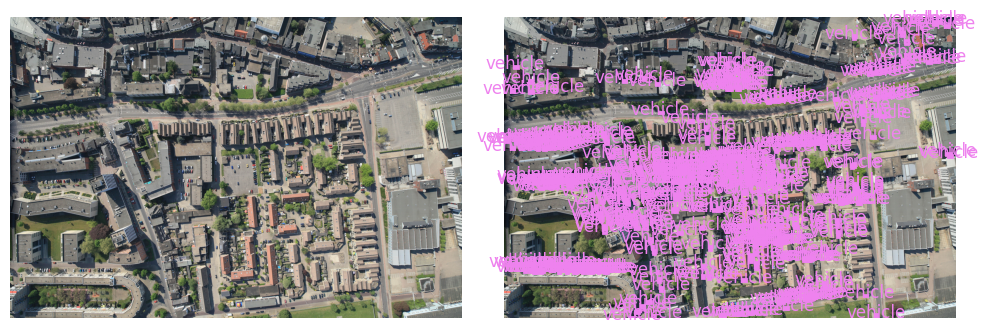

In [ ]:
dataset_config = {
    "data_dir": "./data/ITCVD/Training/Image/",
    "annotation_dir": "./data/ITCVD/Training/GT/",
}
dataset = ITCVDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(5);
dataset.show_image(10);
dataset.show_image(100);

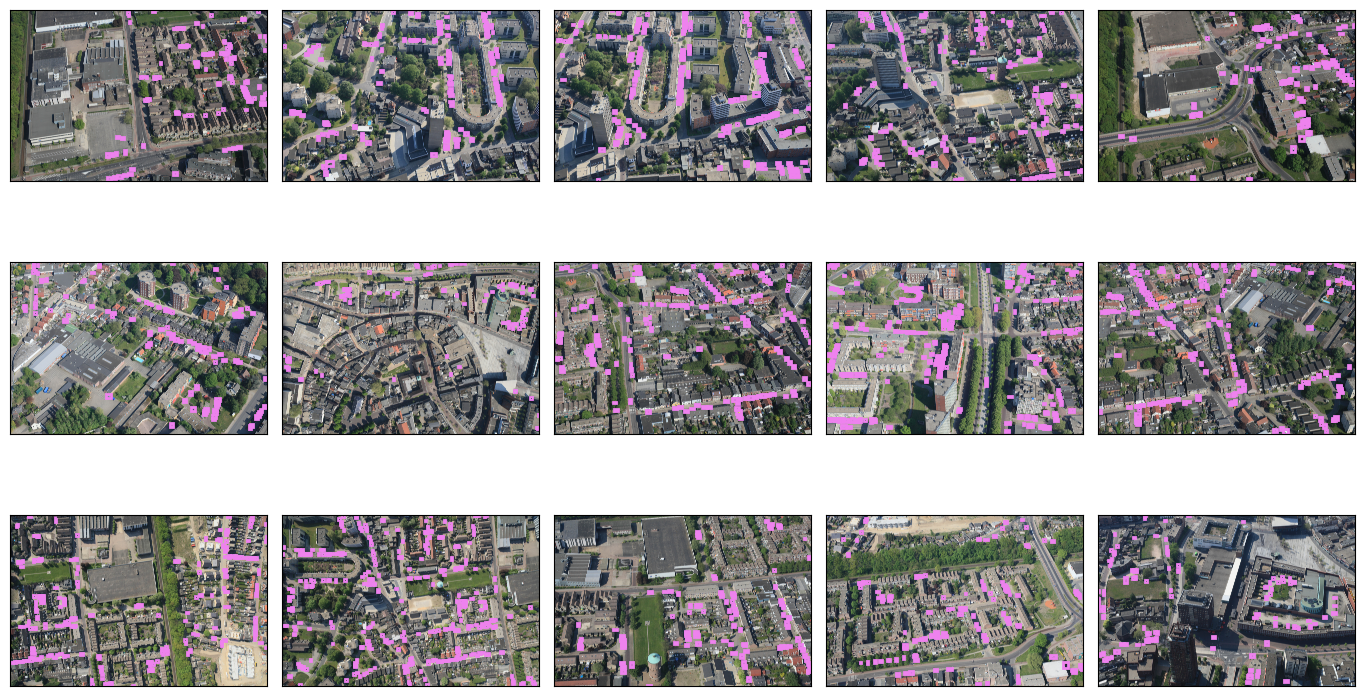

In [19]:
dataset.show_batch(15);

In [42]:
dataset.data_distribution_table()

,Label,Count
0,vehicle,23443


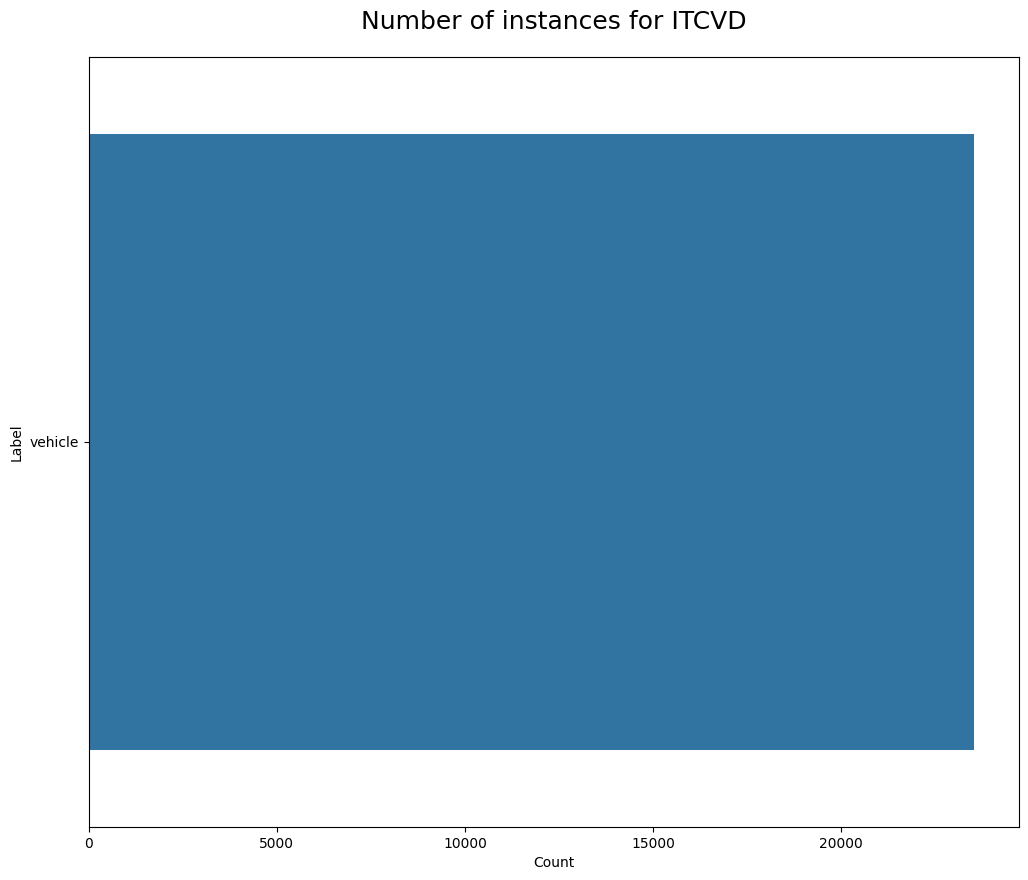

In [30]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/ITCVD/Training/Image/",
    "annotation_dir": "./data/ITCVD/Training/GT/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = ITCVDDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 134


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/ITCVD/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [46]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-26 10:22:30,478 INFO Starting training.
training: 100%|██████████| 17/17 [00:15<00:00,  1.11it/s]
2025-05-26 10:22:45,870 INFO epoch: 1, time: 15, loss:  2.73378
testing on train set: 100%|██████████| 17/17 [00:14<00:00,  1.16it/s]
2025-05-26 10:23:33,530 INFO map:0.011197642423212528, map_50:0.044974375516176224, map_75:0.0007616146467626095, map_small:0.011197731830179691, map_medium:-1.0, map_large:-1.0, mar_1:0.0007336944690905511, mar_10:0.007354007568210363, mar_100:0.027475152164697647, mar_small:0.027475152164697647, mar_medium:-1.0, mar_large:-1.0, map_per_class:0.011197642423212528, mar_100_per_class:0.027475152164697647, classes:1.0
training: 100%|██████████| 17/17 [00:15<00:00,  1.09it/s]
2025-05-26 10:23:49,131 INFO epoch: 2, time: 16, loss:  1.28703
testing on train set: 100%|██████████| 17/17 [00:15<00:00,  1.12it/s]
2025-05-26 10:24:42,777 INFO map:0.026257429271936417, map_50:0.09531368315219879, map_75:0.006052607670426369, map_small:0.026257429271936417, map_

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/ITCVD/Testing/Image/",
    "annotation_dir": "./data/ITCVD/Testing/GT/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = ITCVDDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/ITCVD/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 38


2025-05-26 10:33:26,427 INFO Loading checkpoint /home/dragik/data/FAIR_EO/ITCVD/experiments/checkpoint.pth.tar
2025-05-26 10:33:26,678 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/ITCVD/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 5/5 [00:05<00:00,  1.03s/it]


[{'map': 0.060430578887462616,
  'map_50': 0.15703140199184418,
  'map_75': 0.03224949538707733,
  'map_small': 0.060430578887462616,
  'map_medium': -1.0,
  'map_large': -1.0,
  'mar_1': 0.0033195021096616983,
  'mar_10': 0.02765650302171707,
  'mar_100': 0.09063684195280075,
  'mar_small': 0.09063684195280075,
  'mar_medium': -1.0,
  'mar_large': -1.0,
  'map_per_class': 0.060430578887462616,
  'mar_100_per_class': 0.09063684195280075,
  'classes': 1.0}]

## Predictions

2025-05-26 10:33:40,217 INFO Loading checkpoint /home/dragik/data/FAIR_EO/ITCVD/experiments/checkpoint.pth.tar
2025-05-26 10:33:40,438 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/ITCVD/experiments/checkpoint.pth.tar at epoch 11


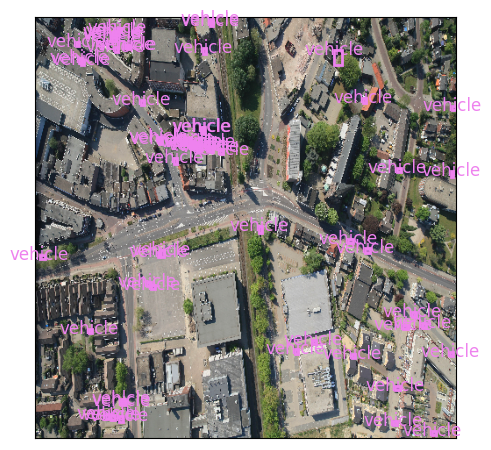

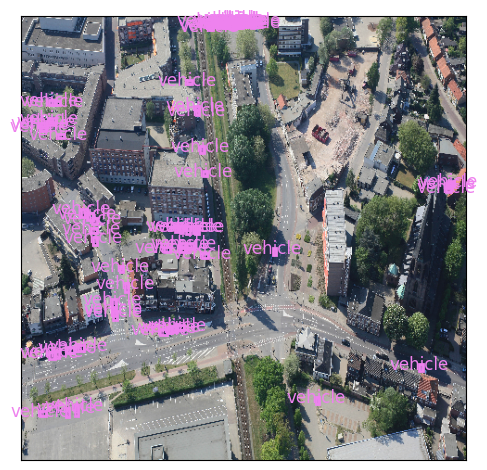

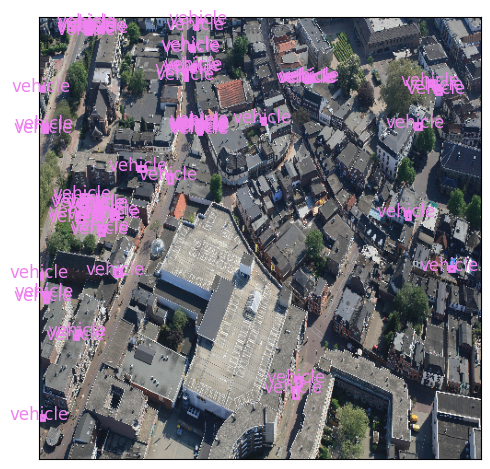

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/ITCVD/experiments/checkpoint.pth.tar"
labels = ["no-data","vehicle"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/ITCVD/Testing/Image/00039.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/ITCVD/Testing/Image/00086.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/ITCVD/Testing/Image/00191.jpg')
fig = model.detect_objects(image, labels, transform)